In [ ]:
import os
import random
import time

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score
)

print("PyTorch version:", torch.__version__)
print("Available GPUs:", torch.cuda.device_count())


TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
!pip install -q torch torchvision


In [ ]:
import torchvision

print("Torchvision version:", torchvision.__version__)


TensorFlow Datasets version: 4.9.10


In [ ]:
!pip install -q importlib-resources

In [ ]:
# Load the TF-Flowers dataset
from torchvision import datasets, transforms
from torchvision.datasets.utils import download_and_extract_archive
from torchvision.transforms import InterpolationMode
from itertools import islice

data_dir = "flower_photos"

if not os.path.isdir(data_dir):
    download_and_extract_archive(
        "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz",
        download_root=".",
        extract_root="."
    )

ds_raw = datasets.ImageFolder(data_dir)

# Get the class names
class_names = ["dandelion", "daisy", "tulips", "sunflowers", "roses"]
ds_raw.target_transform = lambda label: class_names.index(ds_raw.classes[label])

print("Dataset loaded successfully!")
print("Number of images:", len(ds_raw))
print("Number of classes:", len(class_names))
print("Class names:", class_names)


Dataset loaded successfully!
Number of images: 3670
Number of classes: 5
Class names: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']


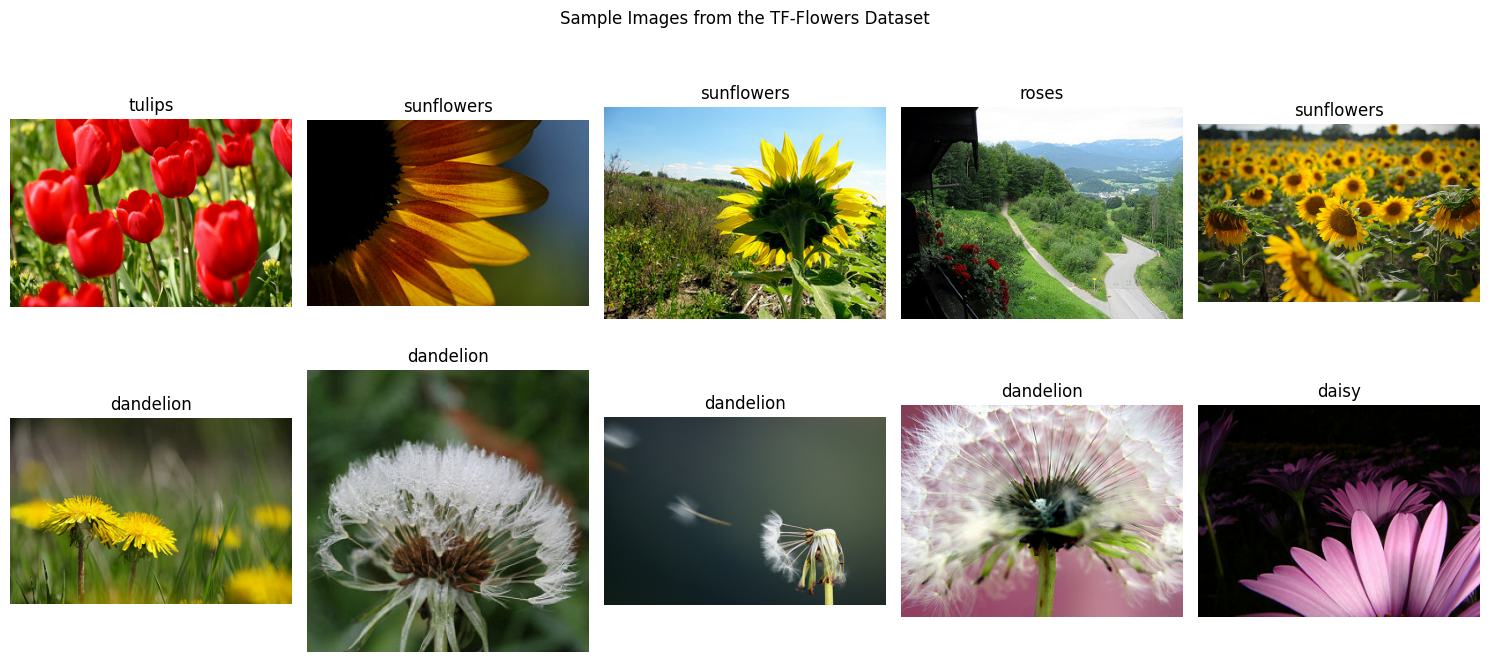

In [ ]:

# Display 10 sample images
fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for i, (image, label) in enumerate(
    islice(ds_raw, 10)
):
    row = i // 5
    col = i % 5

    axes[row, col].imshow(image)
    axes[row, col].set_title(class_names[label])
    axes[row, col].axis("off")

plt.suptitle("Sample Images from the TF-Flowers Dataset")
plt.tight_layout()
plt.show()


In [ ]:
# Inspect the dimensions of the first image
for image, label in islice(ds_raw, 1):
    image = np.array(image)
    print("Image shape:", image.shape)
    print("Image data type:", image.dtype)
    print("Minimum pixel value:", image.min())
    print("Maximum pixel value:", image.max())


Image shape: (333, 500, 3)
Image data type: <dtype: 'uint8'>
Minimum pixel value: 0
Maximum pixel value: 255


In [ ]:
# Step 4: Resize all images to 64 x 64

IMAGE_SIZE = (64, 64)

images = []
labels = []

for image, label in ds_raw:

    # Resize the image
    image = transforms.functional.resize(
        transforms.functional.pil_to_tensor(image).float(),
        IMAGE_SIZE,
        interpolation=InterpolationMode.BILINEAR,
        antialias=True
    )

    # Convert to uint8
    image = image.permute(1, 2, 0).byte().numpy()

    images.append(image)
    labels.append(int(label))

# Convert lists to NumPy arrays
X = np.stack(images)
y = np.array(labels, dtype=np.int64)

print("Images shape:", X.shape)
print("Labels shape:", y.shape)
print("Image data type:", X.dtype)
print("Minimum pixel value:", X.min())
print("Maximum pixel value:", X.max())


Images shape: (3670, 64, 64, 3)
Labels shape: (3670,)
Image data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255


In [ ]:
# Step 5: Split the dataset into 70%, 15%, and 15%

# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: divide the remaining 30% equally
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))

print("\nTotal images:", len(X_train) + len(X_val) + len(X_test))

Training images: 2569
Validation images: 550
Testing images: 551

Total images: 3670


In [ ]:
# Check how many images from each class are in each subset

class_summary = pd.DataFrame({
    "Class": class_names,
    "Training": [
        np.sum(y_train == i) for i in range(len(class_names))
    ],
    "Validation": [
        np.sum(y_val == i) for i in range(len(class_names))
    ],
    "Testing": [
        np.sum(y_test == i) for i in range(len(class_names))
    ]
})

display(class_summary)

,Class,Training,Validation,Testing
0,dandelion,629,134,135
1,daisy,443,95,95
2,tulips,559,120,120
3,sunflowers,489,105,105
4,roses,449,96,96


In [ ]:
# Step 6: Normalize the images to the range [0, 1]

X_train_norm = X_train.astype("float32") / 255.0
X_val_norm = X_val.astype("float32") / 255.0
X_test_norm = X_test.astype("float32") / 255.0

print("Training data shape:", X_train_norm.shape)
print("Validation data shape:", X_val_norm.shape)
print("Testing data shape:", X_test_norm.shape)

print("\nTraining pixel range:")
print("Minimum:", X_train_norm.min())
print("Maximum:", X_train_norm.max())

print("\nData type:", X_train_norm.dtype)

Training data shape: (2569, 64, 64, 3)
Validation data shape: (550, 64, 64, 3)
Testing data shape: (551, 64, 64, 3)

Training pixel range:
Minimum: 0.0
Maximum: 1.0

Data type: float32


In [ ]:
# Step 7: Build Model A - Standard CNN

model_a = nn.Sequential(

    # Convolution block 1
    nn.Conv2d(
        3, 16, kernel_size=(3, 3),
        padding="same"
    ),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=(2, 2)),

    # Convolution block 2
    nn.Conv2d(
        16, 32, kernel_size=(3, 3),
        padding="same"
    ),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=(2, 2)),

    # Convolution block 3
    nn.Conv2d(
        32, 64, kernel_size=(3, 3),
        padding="same"
    ),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=(2, 2)),

    # Classification head
    nn.Flatten(),
    nn.Linear(64 * 8 * 8, 64),
    nn.ReLU(),
    nn.Linear(64, len(class_names))
)

# Display the architecture
print(model_a)


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 64, 64, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 286,117 (1.09 MB)

 Trainable params: 286,117 (1.09 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Step 8: Build Model B - Lightweight CNN

model_b = nn.Sequential(

    # Initial standard convolution
    nn.Conv2d(
        3, 8, kernel_size=3,
        padding="same"
    ),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),

    # Depthwise separable convolution block 1
    nn.Conv2d(8, 8, kernel_size=3, padding="same", groups=8, bias=False),
    nn.Conv2d(8, 16, kernel_size=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),

    # Depthwise separable convolution block 2
    nn.Conv2d(16, 16, kernel_size=3, padding="same", groups=16, bias=False),
    nn.Conv2d(16, 32, kernel_size=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),

    # Depthwise separable convolution block 3
    nn.Conv2d(32, 32, kernel_size=3, padding="same", groups=32, bias=False),
    nn.Conv2d(32, 48, kernel_size=1),
    nn.ReLU(),

    # Compact classification head
    nn.AdaptiveAvgPool2d(1),
    nn.Flatten(),
    nn.Linear(48, 32),
    nn.ReLU(),
    nn.Linear(32, len(class_names))
)

# Display the architecture
print(model_b)

# Verify the assignment's parameter constraint
trainable_params_b = sum(p.numel() for p in model_b.parameters() if p.requires_grad)

print("\nModel B trainable parameters:", trainable_params_b)
print("Meets fewer-than-100,000 requirement:",
      trainable_params_b < 100_000)

assert trainable_params_b < 100_000, \
    "Model B exceeds the 100,000-parameter limit!"


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_15 (Conv2D)              │ (None, 64, 64, 8)      │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_21 (MaxPooling2D) │ (None, 32, 32, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_9              │ (None, 32, 32, 16)     │           216 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_22 (MaxPooling2D) │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_10             │ (None, 16, 16, 32)     │           688 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_23 (MaxPooling2D) │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_11             │ (None, 8, 8, 48)       │         1,872 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 48)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 32)             │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,733 (18.49 KB)

 Trainable params: 4,733 (18.49 KB)

 Non-trainable params: 0 (0.00 B)


Model B trainable parameters: 4733
Meets fewer-than-100,000 requirement: True


In [ ]:
# Step 9: Configure Model A with Adam

from torch.utils.data import TensorDataset, DataLoader
from types import SimpleNamespace
import copy

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
criterion = nn.CrossEntropyLoss()

train_dataset = TensorDataset(
    torch.from_numpy(X_train_norm).permute(0, 3, 1, 2).contiguous(),
    torch.from_numpy(y_train)
)
val_dataset = TensorDataset(
    torch.from_numpy(X_val_norm).permute(0, 3, 1, 2).contiguous(),
    torch.from_numpy(y_val)
)

def train_model(model, optimizer, epochs, batch_size=32, verbose=1):
    model.to(device)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size)
    metrics = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}

    for epoch in range(epochs):
        model.train()
        train_loss, train_correct = 0.0, 0

        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * targets.size(0)
            train_correct += (outputs.argmax(dim=1) == targets).sum().item()

        model.eval()
        val_loss, val_correct = 0.0, 0
        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                val_loss += loss.item() * targets.size(0)
                val_correct += (outputs.argmax(dim=1) == targets).sum().item()

        metrics["loss"].append(train_loss / len(train_dataset))
        metrics["accuracy"].append(train_correct / len(train_dataset))
        metrics["val_loss"].append(val_loss / len(val_dataset))
        metrics["val_accuracy"].append(val_correct / len(val_dataset))

        if verbose:
            print(f"Epoch {epoch + 1}/{epochs} - "
                  f"loss: {metrics['loss'][-1]:.4f} - "
                  f"accuracy: {metrics['accuracy'][-1]:.4f} - "
                  f"val_loss: {metrics['val_loss'][-1]:.4f} - "
                  f"val_accuracy: {metrics['val_accuracy'][-1]:.4f}")

    return SimpleNamespace(history=metrics)

def fresh_model(model):
    cloned = copy.deepcopy(model)
    for layer in cloned.modules():
        if hasattr(layer, "reset_parameters"):
            layer.reset_parameters()
    return cloned.to(device)

def predict_probabilities(model, X, batch_size=32):
    model.eval()
    batches = DataLoader(
        torch.from_numpy(X).permute(0, 3, 1, 2).contiguous(),
        batch_size=batch_size
    )
    probabilities = []
    with torch.no_grad():
        for inputs in batches:
            outputs = model(inputs.to(device))
            probabilities.append(torch.softmax(outputs, dim=1).cpu().numpy())
    return np.concatenate(probabilities, axis=0)

model_a.to(device)
optimizer_a = optim.Adam(model_a.parameters(), lr=0.001)

print("Model A compiled successfully.")
print("Optimizer: Adam")
print("Learning rate: 0.001")
print("Loss function: Sparse categorical cross-entropy")


Model A compiled successfully.
Optimizer: Adam
Learning rate: 0.001
Loss function: Sparse categorical cross-entropy


In [ ]:
# Step 10: Preliminary optimizer comparison

optimizers = {
    "SGD": lambda params: optim.SGD(params, lr=0.01),
    "SGD with Momentum": lambda params: optim.SGD(
        params,
        lr=0.01,
        momentum=0.9
    ),
    "Adam": lambda params: optim.Adam(params, lr=0.001)
}

optimizer_results = []

for optimizer_name, optimizer_factory in optimizers.items():

    print(f"\nTraining Model A with {optimizer_name}...")

    # Create a fresh model so each optimizer starts from the same
    # initial weights.
    model = copy.deepcopy(model_a)
    model.load_state_dict(model_a.state_dict())
    optimizer = optimizer_factory(model.parameters())

    start_time = time.time()

    history = train_model(
        model,
        optimizer,
        epochs=5,
        batch_size=32,
        verbose=1
    )

    elapsed_time = time.time() - start_time

    optimizer_results.append({
        "Optimizer": optimizer_name,
        "Final Training Accuracy": history.history["accuracy"][-1],
        "Final Validation Accuracy": history.history["val_accuracy"][-1],
        "Final Training Loss": history.history["loss"][-1],
        "Final Validation Loss": history.history["val_loss"][-1],
        "Total Training Time (s)": elapsed_time,
        "Average Time per Epoch (s)": elapsed_time / 5
    })

optimizer_df = pd.DataFrame(optimizer_results)

print("\nOptimizer Comparison Results:")
display(optimizer_df.round(4))



Training Model A with SGD...
Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.2795 - loss: 1.5854 - val_accuracy: 0.2436 - val_loss: 1.5902
Epoch 2/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.3585 - loss: 1.5254 - val_accuracy: 0.3491 - val_loss: 1.4991
Epoch 3/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3819 - loss: 1.4473 - val_accuracy: 0.3764 - val_loss: 1.4394
Epoch 4/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.4239 - loss: 1.3649 - val_accuracy: 0.3091 - val_loss: 1.6696
Epoch 5/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4745 - loss: 1.2929 - val_accuracy: 0.4636 - val_loss: 1.2506

Training Model A with SGD with Momentum...
Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.3488 - loss: 1.4901 - val_accuracy: 0.4782 - val_loss: 1.4163
Epoch 2/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.4800 - loss: 1.2317 - val_accuracy: 0.5255 - val_loss: 1.1549
Epoch 3/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step 

,Optimizer,Final Training Accuracy,Final Validation Accuracy,Final Training Loss,Final Validation Loss,Total Training Time (s),Average Time per Epoch (s)
0,SGD,0.4745,0.4636,1.2929,1.2506,6.6094,1.3219
1,SGD with Momentum,0.6049,0.6091,0.9853,0.9914,7.0113,1.4023
2,Adam,0.6878,0.6382,0.8106,0.9303,8.3615,1.6723


In [ ]:
# Step 11: Train Model A for 20 epochs

# Create a fresh Model A
model_a_final = fresh_model(model_a)

# Compile using the selected optimizer
optimizer_a_final = optim.Adam(model_a_final.parameters(), lr=0.001)

# Measure training time
start_time = time.time()

history_a = train_model(
    model_a_final,
    optimizer_a_final,
    epochs=20,
    batch_size=32,
    verbose=1
)

time_a = time.time() - start_time

print(f"\nModel A total training time: {time_a:.2f} seconds")
print(f"Average time per epoch: {time_a / 20:.2f} seconds")


Epoch 1/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - accuracy: 0.3784 - loss: 1.4052 - val_accuracy: 0.4800 - val_loss: 1.1993
Epoch 2/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.5162 - loss: 1.1627 - val_accuracy: 0.5073 - val_loss: 1.1370
Epoch 3/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5831 - loss: 1.0465 - val_accuracy: 0.5545 - val_loss: 1.0596
Epoch 4/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6411 - loss: 0.9371 - val_accuracy: 0.6000 - val_loss: 0.9951
Epoch 5/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6497 - loss: 0.8852 - val_accuracy: 0.6273 - val_loss: 0.9937
Epoch 6/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6948 - loss: 0.7863 - val_accuracy: 0.6273 - val_loss: 0.9554
Epoch 7/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7248 - loss: 0.7206 - val_accuracy: 0.6709 - val_loss: 0.9100
Epoch 8/20
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7509 - loss: 0.6602 - val_accuracy: 0.6527 - val_loss

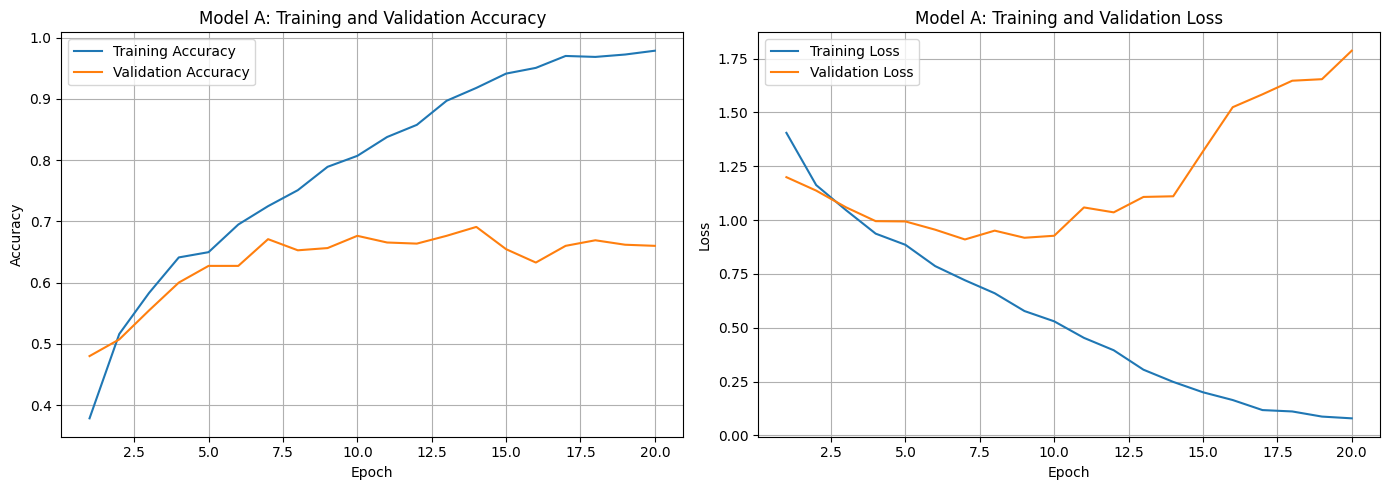

In [ ]:
# Step 12: Plot Model A training history

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

epochs_range = range(1, len(history_a.history["loss"]) + 1)

# Accuracy curves
axes[0].plot(
    epochs_range,
    history_a.history["accuracy"],
    label="Training Accuracy"
)
axes[0].plot(
    epochs_range,
    history_a.history["val_accuracy"],
    label="Validation Accuracy"
)
axes[0].set_title("Model A: Training and Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Loss curves
axes[1].plot(
    epochs_range,
    history_a.history["loss"],
    label="Training Loss"
)
axes[1].plot(
    epochs_range,
    history_a.history["val_loss"],
    label="Validation Loss"
)
axes[1].set_title("Model A: Training and Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# Step 13: Train Model B for 20 epochs

# Create a fresh Model B
model_b_final = fresh_model(model_b)

# Compile with the same optimizer and loss
optimizer_b_final = optim.Adam(model_b_final.parameters(), lr=0.001)

# Measure training time
start_time = time.time()

history_b = train_model(
    model_b_final,
    optimizer_b_final,
    epochs=150,
    batch_size=32,
    verbose=1
)

time_b = time.time() - start_time

print(f"\nModel B total training time: {time_b:.2f} seconds")
print(f"Average time per epoch: {time_b / 20:.2f} seconds")


Epoch 1/150
81/81 ━━━━━━━━━━━━━━━━━━━━ 7s 40ms/step - accuracy: 0.2655 - loss: 1.5907 - val_accuracy: 0.3291 - val_loss: 1.5344
Epoch 2/150
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3749 - loss: 1.4157 - val_accuracy: 0.4055 - val_loss: 1.3192
Epoch 3/150
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.4231 - loss: 1.3056 - val_accuracy: 0.4709 - val_loss: 1.2513
Epoch 4/150
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4694 - loss: 1.2476 - val_accuracy: 0.4873 - val_loss: 1.1925
Epoch 5/150
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4753 - loss: 1.2027 - val_accuracy: 0.4891 - val_loss: 1.1698
Epoch 6/150
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5053 - loss: 1.1728 - val_accuracy: 0.5473 - val_loss: 1.1523
Epoch 7/150
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5271 - loss: 1.1431 - val_accuracy: 0.5145 - val_loss: 1.1574
Epoch 8/150
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5415 - loss: 1.1182 - val_accuracy: 0.5418 - 

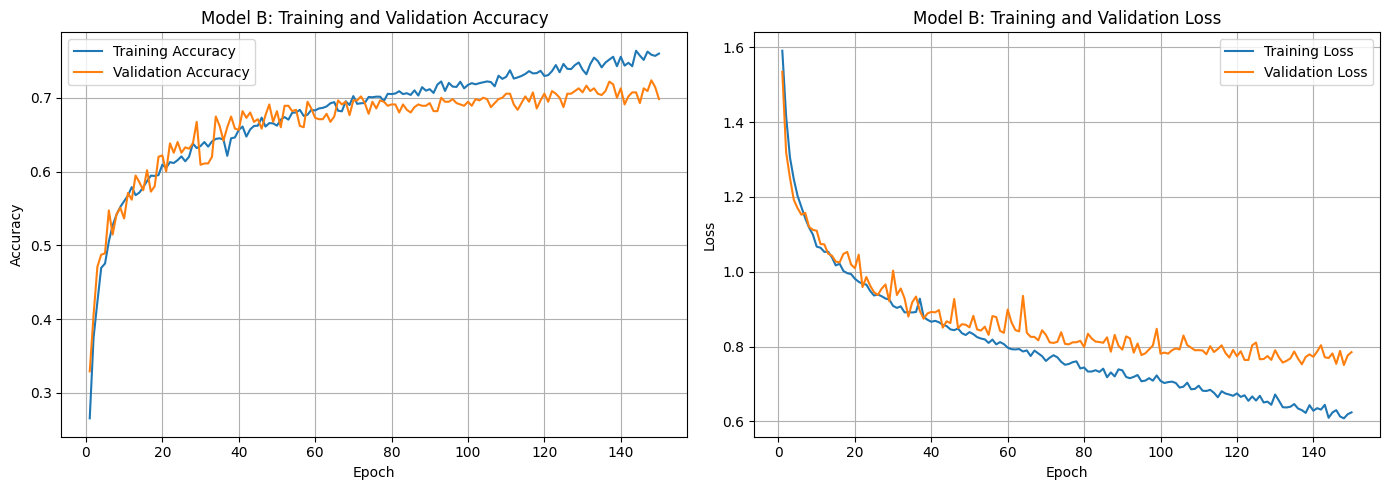

In [ ]:
# Step 15: Plot Model B training history

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

epochs_range = range(1, len(history_b.history["loss"]) + 1)

# Accuracy curves
axes[0].plot(
    epochs_range,
    history_b.history["accuracy"],
    label="Training Accuracy"
)
axes[0].plot(
    epochs_range,
    history_b.history["val_accuracy"],
    label="Validation Accuracy"
)
axes[0].set_title("Model B: Training and Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Loss curves
axes[1].plot(
    epochs_range,
    history_b.history["loss"],
    label="Training Loss"
)
axes[1].plot(
    epochs_range,
    history_b.history["val_loss"],
    label="Validation Loss"
)
axes[1].set_title("Model B: Training and Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


Model A - Standard CNN
Test accuracy: 0.6588
Macro precision: 0.6667
Macro recall: 0.6566

Classification Report:
              precision    recall  f1-score   support

   dandelion       0.67      0.78      0.72       135
       daisy       0.67      0.67      0.67        95
      tulips       0.75      0.47      0.58       120
  sunflowers       0.75      0.75      0.75       105
       roses       0.50      0.60      0.54        96

    accuracy                           0.66       551
   macro avg       0.67      0.66      0.65       551
weighted avg       0.67      0.66      0.66       551



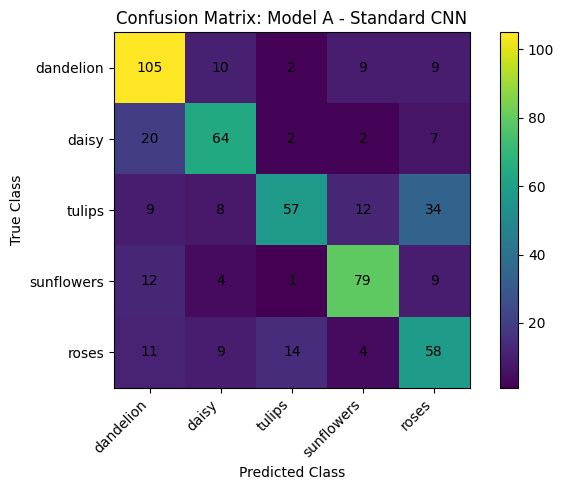


Model B - Lightweight CNN
Test accuracy: 0.7096
Macro precision: 0.7085
Macro recall: 0.7115

Classification Report:
              precision    recall  f1-score   support

   dandelion       0.77      0.65      0.70       135
       daisy       0.71      0.84      0.77        95
      tulips       0.66      0.74      0.70       120
  sunflowers       0.75      0.79      0.77       105
       roses       0.66      0.53      0.59        96

    accuracy                           0.71       551
   macro avg       0.71      0.71      0.71       551
weighted avg       0.71      0.71      0.71       551



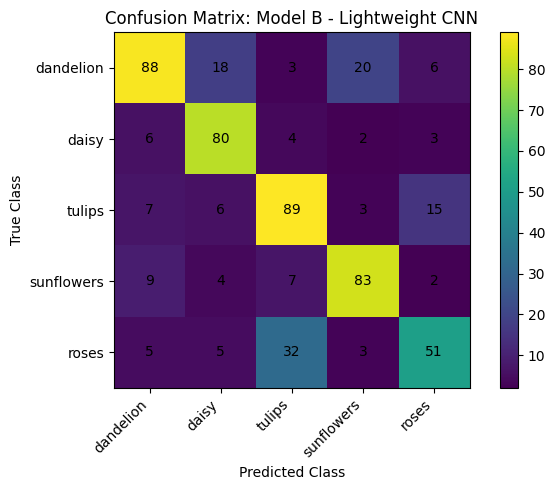


Custom CNN Test Results:


,Accuracy,Macro Precision,Macro Recall
Model A - Standard CNN,0.6588,0.6667,0.6566
Model B - Lightweight CNN,0.7096,0.7085,0.7115


In [ ]:
# Step 16: Evaluate both custom CNN models

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score
)

custom_models = {
    "Model A - Standard CNN": model_a_final,
    "Model B - Lightweight CNN": model_b_final
}

test_results = {}

for model_name, model in custom_models.items():

    print(f"\n{'=' * 60}")
    print(model_name)
    print("=" * 60)

    # Predict probabilities for the test images
    y_prob = predict_probabilities(model, X_test_norm)

    # Convert probabilities into predicted class labels
    y_pred = np.argmax(y_prob, axis=1)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, average="macro", zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, average="macro", zero_division=0
    )

    test_results[model_name] = {
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall
    }

    print(f"Test accuracy: {accuracy:.4f}")
    print(f"Macro precision: {precision:.4f}")
    print(f"Macro recall: {recall:.4f}")

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        zero_division=0
    ))

    # Plot the confusion matrix
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=np.arange(len(class_names))
    )

    plt.figure(figsize=(7, 5))
    plt.imshow(cm)
    plt.title(f"Confusion Matrix: {model_name}")
    plt.xlabel("Predicted Class")
    plt.ylabel("True Class")
    plt.xticks(
        np.arange(len(class_names)),
        class_names,
        rotation=45,
        ha="right"
    )
    plt.yticks(np.arange(len(class_names)), class_names)
    plt.colorbar()

    for i in range(len(class_names)):
        for j in range(len(class_names)):
            plt.text(j, i, cm[i, j], ha="center", va="center")

    plt.tight_layout()
    plt.show()

# Summary table
test_results_df = pd.DataFrame(test_results).T
print("\nCustom CNN Test Results:")
display(test_results_df.round(4))


In [ ]:
# Step 18: Summarize custom CNN performance

custom_summary = pd.DataFrame([
    {
        "Model": "Model A - Standard CNN",
        "Trainable Parameters": sum(p.numel() for p in model_a_final.parameters() if p.requires_grad),
        "Training Time (s)": time_a,
        "Average Time per Epoch (s)": time_a / 20,
        "Final Training Accuracy": history_a.history["accuracy"][-1],
        "Final Validation Accuracy": history_a.history["val_accuracy"][-1],
        "Test Accuracy": test_results[
            "Model A - Standard CNN"
        ]["Accuracy"],
        "Macro Precision": test_results[
            "Model A - Standard CNN"
        ]["Macro Precision"],
        "Macro Recall": test_results[
            "Model A - Standard CNN"
        ]["Macro Recall"]
    },
    {
        "Model": "Model B - Lightweight CNN",
        "Trainable Parameters": sum(p.numel() for p in model_b_final.parameters() if p.requires_grad),
        "Training Time (s)": time_b,
        "Average Time per Epoch (s)": time_b / 20,
        "Final Training Accuracy": history_b.history["accuracy"][-1],
        "Final Validation Accuracy": history_b.history["val_accuracy"][-1],
        "Test Accuracy": test_results[
            "Model B - Lightweight CNN"
        ]["Accuracy"],
        "Macro Precision": test_results[
            "Model B - Lightweight CNN"
        ]["Macro Precision"],
        "Macro Recall": test_results[
            "Model B - Lightweight CNN"
        ]["Macro Recall"]
    }
])

display(custom_summary.round(4))


,Model,Trainable Parameters,Training Time (s),Average Time per Epoch (s),Final Training Accuracy,Final Validation Accuracy,Test Accuracy,Macro Precision,Macro Recall
0,Model A - Standard CNN,286117,15.6650,0.7833,0.9786,0.6600,0.6588,0.6667,0.6566
1,Model B - Lightweight CNN,4733,84.2152,4.2108,0.7598,0.6982,0.7096,0.7085,0.7115


In [ ]:
# Step 19: Check pretrained model availability

from torchvision.models import mobilenet_v2, efficientnet_b0

print("MobileNetV2 is available.")
print("EfficientNetB0 is available.")


MobileNetV2 is available.
EfficientNetB0 is available.
